# Project Tape-out

Your name: Athira

# Double Vernier ring

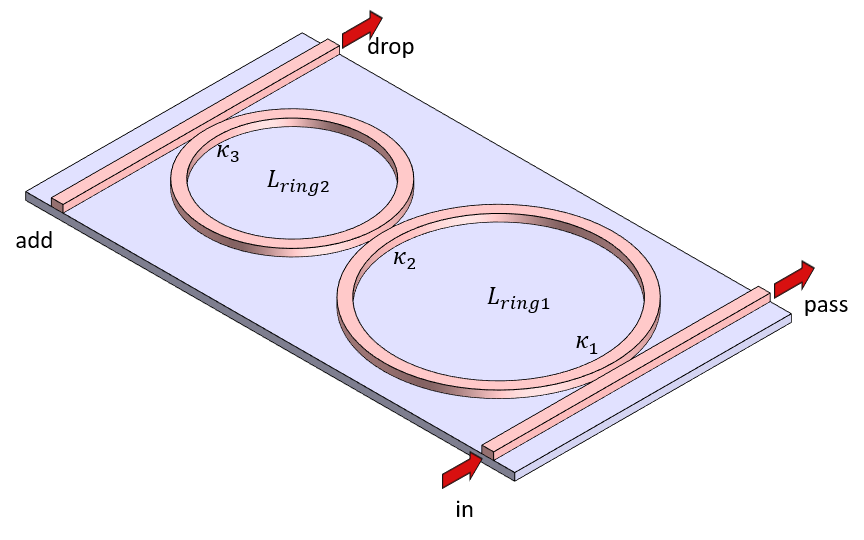 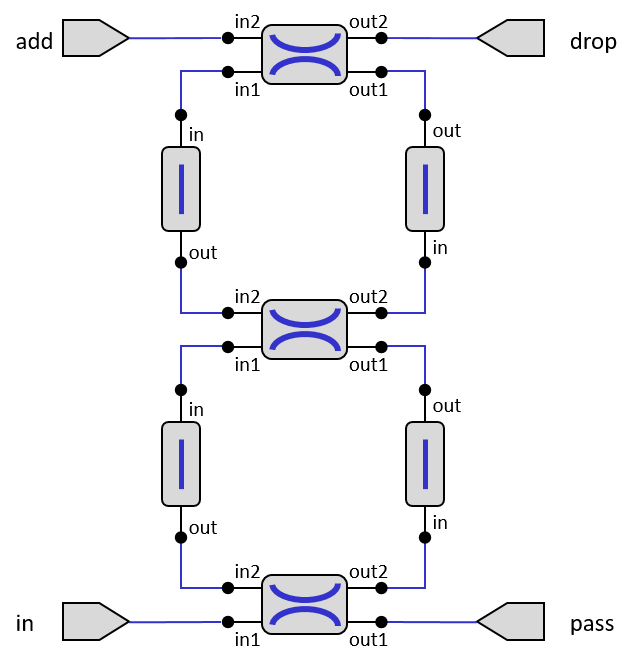

To observe Vernier effect, N*FSR2 = M*FSR1
#
Modelled using 3 directional couplers, with coupling coefficients of 0.1, 0.5 and 0.1 



# Technology

We use the **PRG 2-Layer E-beam** PDK. 

In [118]:

import set_paths

# Load the technology first
from prg_ebeam_2L import technology
import all_utils
from ipkiss3 import all as i3
import numpy as np
import pylab as plt
import matplotlib.pyplot 

In [119]:
from prg_ebeam_2L import all as pdk

# Design Capture
Directional couplers with coupling coefficients 0.1, 0.5, and 0.1 connected using waveguides. To check the effect of coupling coefficient from the input bus waveguide, the combination 0.5, 0.5 and 0.1 is also tested. 
Initially, the combination of FSRs are 2.8 and 2.7 nanometers- referred as circuit1 (for coupling coefficients 0.1, 0.5, 0.1) and ring1 (for coupling coefficients 0.5, 0.5, 0.1)
The second combination of FSRs are 1.4 and 1.3 nanometers- referred as circuit2 and ring2 for the different coupling coefficients.
Maximum length of the rings are decided by FSR. Minimum lengths determined based on the minimum waveguide length required to allow bending of the waveguides. The range of allowed mode numbers(m_min and m_max) are decided for each rings based on the FSR and minimum resonator length requirements. From the allowed ranges of mode numbers, the lowest combination of mode number yielding an FSR greater than 9 nm is selected. The allowed combination of mode pairs correspond to a new set of (larger) FSRs different from the initially specified value.

In [267]:
# specify type of waveguide

In [120]:
wt = pdk.PRG_WG450() #wire waveguide
wt_lo = wt.Layout()
wt_cm = wt.CircuitModel()   

In [268]:
#Function to get the n_eff and n_g values at the resonance wavelength

In [121]:
def parameters(wl_res):
    env_res = i3.Environment(wavelength=wl_res)
    n_eff = wt_cm.get_n_eff(env_res) 
    n_g = wt_cm.get_n_g(env_res)
    return (wl_res, n_eff, n_g)

In [269]:
(wl_res, n_eff, n_g)=parameters(1.55)

In [270]:
#Function to calculate the length of the bend part of the directional coupler

In [271]:
def dir_coup_bend(c):
    dc_ring = pdk.PrgBend90DirectionalCoupler(
                                              trace_template1=wt,
                                              coupling=c)
    dc_ring_lo = dc_ring.Layout()
    bend_length = dc_ring_lo.wg1a.trace_length() + dc_ring_lo.wg1b.trace_length()
    return(bend_length)    

In [272]:
#Functions to calculate the maximum and minimum mode numbers for specific FSR and coupling strengths

In [273]:
def max_mode_num_FSR(fsr):
    Lmax=wl_res ** 2 / (fsr * n_g)
    m_max=(Lmax*n_eff)/wl_res
    return m_max
    
#length of resonator-waveguide should be>0 and large enough for bending (>10 um)
def min_mode_num_dc(c):    
    L = np.arange(40, 150, 0.1)
    n = len(L)
    L_wg=0
    for i in range(n):
         L_ring = L[i]
         L_wg = L_ring * 0.5 - dir_coup_bend(c)
         if L_wg> 10:
             break
    m=(L_ring*n_eff)/wl_res    
    return(m)

In [ ]:
#Mode number combinations larger than the minimum required value, allowing the FSR of the coupled system to be greater than 9 nm.

In [274]:
#find suitable mode numbers satisfying ring resonance condition for 1.55 um and FSR of the vernier ring greater than 9 nm
#fsrc_max is the userdefined upper limit for the FSR of vernier ring. c1 and c2 are coupling coefficients of directional couplers. 
#k is the index corresponding to the chosen pair of mode numbers

def vernier_condition(fsrc_max,c1,c2,k):
    matrix = np.empty((0, 5))
    m1_min=min_mode_num_dc(c1)
    m2_min=min_mode_num_dc(c2)
    m1_max=max_mode_num_FSR(fsr1)
    m2_max=max_mode_num_FSR(fsr2)
    for m1 in range (round(m1_min+1),round(m1_max-1)):
            for m2 in range (round(m2_min+1),round(m2_max-1)):
                L1=m1*wl_res/n_eff
                L2=m2*(wl_res)/n_eff
                if 0<L2-L1 :  #< 200
                    FSRc= wl_res**2/(n_g*abs(L2-L1))
                    if fsrc_max>=FSRc>=0.009:
                        if abs(m1-m2)<150:
                            L1=(m1*wl_res)/n_eff
                            L2=(m2*wl_res)/n_eff
                            new_row = np.array([[m1, m2, FSRc, L1, L2]])
                            matrix = np.vstack((matrix, new_row))
    num_rows = matrix.shape[0]
    if num_rows<1:
        return "error"
    else:
        matrix=matrix[:15, :]
        
        colfsr=matrix[:,2]
        if len(colfsr)>0:
            if matrix[k,3]!=0:
                nfsr1=wl_res**2/(n_g*(matrix[k,3]))
            if matrix[k,4]!=0:
                nfsr2=wl_res**2/(n_g*(matrix[k,4]))
                print(nfsr1, nfsr2)
            
    result=matrix[k]   
    return(result)

In [275]:
def make_wg(ring_length,c):
    L_wg=i3.snap_value(0.5*(ring_length)-dir_coup_bend(c))
    ring_wg = i3.RoundedWaveguide(trace_template=wt)
    ring_wg_lo=ring_wg.Layout(shape=[(0.0, 0.0),(0.0, L_wg)])
    return L_wg, ring_wg

In [276]:
def make_bend_wg(L_wg,c1,c2):
    d=((dir_coup_bend(c1))-(dir_coup_bend(c2)))
    bend_wg=i3.RoundedWaveguide(trace_template=wt)
    bend_wg_lo=bend_wg.Layout(shape=[(0.0, 0.0), (0.0, 0.5*L_wg), (d, 0.5*L_wg),(d, L_wg)])
    return bend_wg

In [277]:
def make_bend_wg2(L_wg,c1,c2):
    d=((dir_coup_bend(c1))-(dir_coup_bend(c2)))
    bend_wg=i3.RoundedWaveguide(trace_template=wt)
    bend_wg_lo=bend_wg.Layout(shape=[(0.0, 0.0), (0.0, 0.5*L_wg), (-d, 0.5*L_wg),(-d, L_wg)])
    return bend_wg

In [279]:
#make vernier ring
def vernier(c1,c2,fsr1,fsr2,fsrc,k):
    #create the directional couplers
    dc_ring1= pdk.PrgBend90DirectionalCoupler(trace_template1=wt,coupling=0.1)
    dc_ring2= pdk.PrgBend90DirectionalCoupler(trace_template1=wt,coupling=0.5)
    dc_ring1.Layout().manhattan=True
    dc_ring2.Layout().manhattan=True

    #selecting mode number and resonator lengths 
    [m1,m2,FSRc,L1,L2]=vernier_condition(fsrc,c1,c2,k)  

    #create the waveguides for the two resonators. one waveguide has to be bend due to difference in coupling coefficients.
    (L_wg1, ring_wg1)=make_wg(L1,c1)
    (L_wg2, ring_wg2)=make_wg(L2,c2)
    ring_wg1_bend=make_bend_wg(L_wg1,c1,c2)
    ring_wg2_bend=make_bend_wg2(L_wg2,c1,c2)

    #circuit1 with coupling coeff: 0.1, 0.5, 0.1
    from routing import AutoPlaceAndConnect
    ring_circuit = AutoPlaceAndConnect(child_cells={
                                                  "dc_top": dc_ring1,
                                                  "dc_middle": dc_ring2,
                                                  "dc_down": dc_ring1,
                                                   "wg_top_l":ring_wg1,
                                                   "wg_top_r":ring_wg1_bend,
                                                   "wg_bottom_l":ring_wg2,
                                                   "wg_bottom_r":ring_wg2_bend,
                                                   
                                                  },          
                                           links=[
                                                  ("dc_top:in1", "wg_top_l:out"),
                                                  ("dc_top:out1", "wg_top_r:out"),
                                                  ("wg_top_l:in", "dc_middle:in2"),
                                                  ("wg_top_r:in", "dc_middle:out2"),
                                                  ("dc_middle:in1","wg_bottom_l:out"),
                                                  ("dc_middle:out1","wg_bottom_r:in"),
                                                  ("wg_bottom_l:in", "dc_down:in2"),
                                                  ("wg_bottom_r:out", "dc_down:out2"),
                                                  
                                                 ],
                                           external_port_names = {"dc_top:in2":"add",
                                                                  "dc_top:out2":"drop",
                                                                 "dc_down:in1":"in",
                                                                  "dc_down:out1":"pass"}
                                         )

    ring_circuit_layout = ring_circuit.Layout()
    ring_circuit_layout.manhattan=True
    #ring_circuit_layout.visualize(annotate=True)
    ######################################################################################################################

    #circuit2 with coupling coeff: 0.5, 0.5, 0.1
    
    from routing import AutoPlaceAndConnect
    ring_circuit2 = AutoPlaceAndConnect(child_cells={
                                                  "dc_top": dc_ring1,
                                                  "dc_middle": dc_ring2,
                                                  "dc_down": dc_ring2,
                                                   "wg_top_l":ring_wg1,
                                                   "wg_top_r":ring_wg1_bend,
                                                   "wg_bottom_l":ring_wg2,
                                                   "wg_bottom_r":ring_wg2,
                                                   
                                                  },          
                                           links=[
                                                  ("dc_top:in1", "wg_top_l:out"),
                                                  ("dc_top:out1", "wg_top_r:out"),
                                                  ("wg_top_l:in", "dc_middle:in2"),
                                                  ("wg_top_r:in", "dc_middle:out2"),
                                                  ("dc_middle:in1","wg_bottom_l:out"),
                                                  ("dc_middle:out1","wg_bottom_r:in"),
                                                  ("wg_bottom_l:in", "dc_down:in2"),
                                                  ("wg_bottom_r:out", "dc_down:out2"),
                                                  
                                                 ],
                                           external_port_names = {"dc_top:in2":"add",
                                                                  "dc_top:out2":"drop",
                                                                 "dc_down:in1":"in",
                                                                  "dc_down:out1":"pass"}
                                         )

    ring_circuit2_layout = ring_circuit2.Layout()
    ring_circuit2_layout.manhattan=True
    #ring_circuit2_layout.visualize(annotate=True)    

    return (ring_circuit,ring_circuit2)


In [284]:
#First combination of FSR1 and FSR2
k=0
c1=0.1
c2=0.5
fsr1=0.0028
fsr2=0.0027
fsrc=(fsr1*fsr2)/(abs(fsr2-fsr1))
(circ1,circ2)=vernier(c1,c2,fsr1,fsr2,fsrc,k)

0.006863084795561516 0.005385615152072578


In [288]:
#The allowed combinations of m1, m2, vernier FSR>0.009 having resonance at 1.55 um requires individual rings to have the FSRs of 6.86 nm and 5.385 nm

In [286]:
#Second combination of FSR1 and FSR2
c1=0.1
c2=0.5
fsr1=0.0014
fsr2=0.0013
fsrc=fsr1*fsr2/(abs(fsr1-fsr2))
k=0
(circ_n1,circ_n2)=vernier(c1,c2,fsr1,fsr2,fsrc,k)

0.006863084795561516 0.0049713370634516104


In [283]:
#The allowed combinations of m1, m2, vernier FSR>0.009 having resonance at 1.55 um requires individual rings to have the FSRs of 6.86 nm and 4.97 nm

# Simulate the circuit

Check your circuit behaviour. Choose your parameters.
document your choices.

<Figure size 640x480 with 0 Axes>

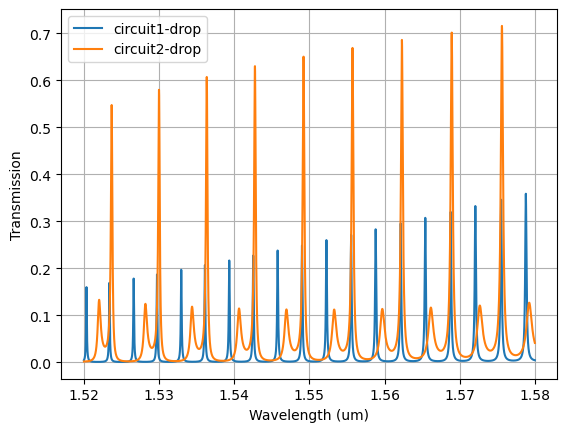

In [293]:
matplotlib.pyplot.close()
sim_wavelengths=np.linspace(1.520, 1.580, 8001)

circ1_cm = circ1.CircuitModel()
circ2_cm = circ2.CircuitModel()
circ_n1_cm = circ1.CircuitModel()
circ_n2_cm = circ2.CircuitModel()

sm1 = circ1_cm.get_smatrix(wavelengths=sim_wavelengths)
sm2 = circ2_cm.get_smatrix(wavelengths=sim_wavelengths)
sm3 = circ_n1_cm.get_smatrix(wavelengths=sim_wavelengths)
sm4 = circ_n2_cm.get_smatrix(wavelengths=sim_wavelengths)

plt.figure()
fig, ax = plt.subplots() 
plt.plot(sim_wavelengths, (np.abs(sm1['in', 'drop'])**2), label='circuit1-drop')
plt.plot(sim_wavelengths, (np.abs(sm2['in', 'drop'])**2), label='circuit2-drop')
#plt.plot(sim_wavelengths, (np.abs(sm3['in', 'drop'])**2), label='circuit1n-drop')
#plt.plot(sim_wavelengths, (np.abs(sm4['in', 'drop'])**2), label='circuit2n-drop')

#not much difference between the two fsr combinations!

ax.legend()
ax.set_xlabel("Wavelength (um)")
ax.set_ylabel("Transmission")
ax.grid(True)

#import pickle
#with open('set3_drop_k0.fig.pickle', 'wb') as f:
#    pickle.dump(fig, f)

# Make a frame

The frame can have up to 8 grating couplers on both sides. Don't place more couplers than necessary. 

In [294]:
coupled_rings= pdk.PRG_FIBER_FRAME_8(name="coupled_rings",  #give all your components a good name. This is not a good name!
                                 title="Coupled Rings",
                                 owner="Athira",
                                 n_inputs=4,
                                 n_outputs=8)

coupled_rings_lo = coupled_rings.Layout()
#coupled_rings_lo.visualize(annotate=True)

# Put the circuit in the frame

connect your circuit element in a frame. Add alignment waveguides or component tests if needed.

In [295]:
ak_frame = pdk.PRG_FIBER_FRAME_8(name="ak_frame",  
                                 title="Vernier Rings",
                                 owner="ak",
                                 n_inputs=4,
                                 n_outputs=8)
ak_frame_lo = ak_frame.Layout()
#ak_frame_lo.visualize(annotate=True)

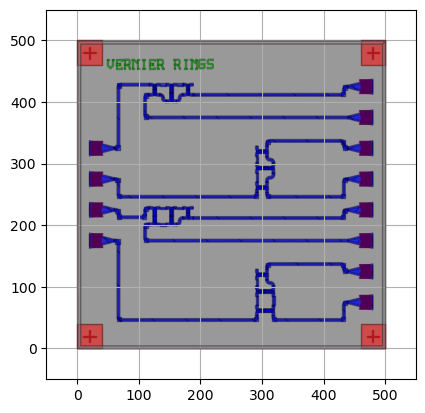

In [296]:
#put circuit in frame
from routing import PlaceAndAutoRoute

# only 2 cells: the circuit and the frame
child_cells = {"circuit": circ1,
               "circuit2": circ1_n,
               "ring1": circ2,      #one resonator looks like a ring
               "ring2": circ2_n,    #one resonator looks like a ring             
               "frame": ak_frame}

# connect your circuit ports to the on-chip ports of the frame
links = [("circuit:in", "frame:p_in4"),
         ("circuit:pass", "frame:p_out7"),
         ("circuit:drop", "frame:p_out8"),
         ("ring2:in", "frame:p_in1"),
         ("ring2:drop", "frame:p_out2"),
         ("ring2:pass", "frame:p_out1"),
         ("circuit2:pass", "frame:p_out5"),
         ("ring1:pass", "frame:p_out3"),
         ("ring1:in", "frame:p_in2"),
         ("ring1:drop", "frame:p_out4"),
         ("circuit2:in", "frame:p_in3"),
         ("circuit2:drop", "frame:p_out6"),
         ] 

external_port_names = {"frame:in1": "in1",
                       "frame:in2": "in2",
                       "frame:in3": "in3",
                       "frame:in4": "in4",
                       "frame:out1": "out1",
                       "frame:out2": "out2",
                       "frame:out3": "out3",
                       "frame:out4": "out4",
                       "frame:out5": "out5",
                       "frame:out6": "out6",
                       "frame:out7": "out7",
                       "frame:out8": "out8",
                      }

child_transformations = {"circuit": i3.Rotation(rotation=-90) + i3.Translation((180.0, 420.0)),
                         "circuit2":i3.Rotation(rotation=0) + i3.Translation((300.0, 320.0)),
                        "ring2":i3.Rotation(rotation=0) + i3.Translation((300.0, 120.0)),
                        "ring1":i3.Rotation(rotation=-90) + i3.Translation((180.0, 220.0))}

ak_chip = PlaceAndAutoRoute(name="ak_chip",
                            child_cells=child_cells,
                            links=links,
                            external_port_names=external_port_names )
ak_chip_layout = ak_chip.Layout(child_transformations=child_transformations)
ak_chip_layout.manhattan = True
ak_chip_layout.visualize(annotate=False)
#matplotlib.pyplot.close()



# Resimulate

Resimulate the circuit. You should get the same response, but with the curve of the grating couplers superimposed.

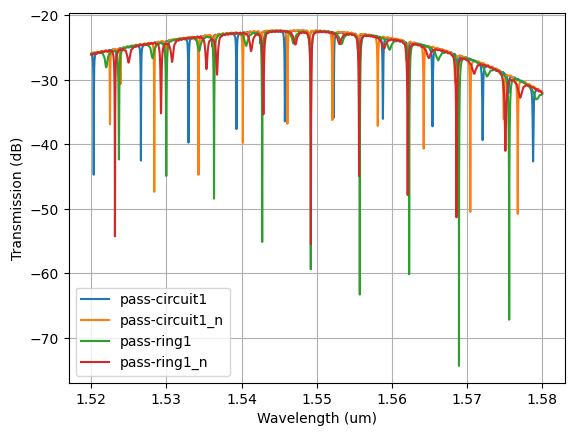

In [298]:
matplotlib.pyplot.close()
ak_chip_cm=ak_chip.CircuitModel()
sim_wavelengths=np.linspace(1.520, 1.580, 8001)
sm1 = ak_chip_cm.get_smatrix(wavelengths=sim_wavelengths)

fig, ax = plt.subplots()       
plt.plot(sim_wavelengths, 10*np.log10(np.abs(sm1['in4', 'out7'])**2), label='pass-circuit1')
plt.plot(sim_wavelengths, 10*np.log10(np.abs(sm1['in3', 'out5'])**2), label='pass-circuit1_n')
plt.plot(sim_wavelengths, 10*np.log10(np.abs(sm1['in2', 'out3'])**2), label='pass-ring1')#different coupling coeff
plt.plot(sim_wavelengths, 10*np.log10(np.abs(sm1['in1', 'out1'])**2), label='pass-ring1_n')#different coupling coeff
ax.legend()
ax.set_xlabel("Wavelength (um)")
ax.set_ylabel("Transmission (dB)")
ax.grid(True)

#import pickle
#with open('set3_pass_k0.fig.pickle', 'wb') as f:
 #   pickle.dump(fig, f)

# Design Rule Check

Run the DRC check. 

If the DRC returns errors, try to fix them. You can always send a subcircuit to the DRC process to see where the exact problem is. You can:

- perform explicit grid snapping
- flatten non-orthogonal references
- add `manhattan` blocks to wavegudie bends.

In [299]:
# find the DRC file. It is located relative to the Technology deck

import os
technology.__file__
pdk_path = os.path.abspath(os.path.join(os.path.split(technology.__file__)[0],
                                        "../../../"))
calibre_drc_deck = os.path.join(pdk_path, "drc", "prg_ebeam_2L_drc_deck.cal")

Set up the DRC connection

In [300]:
from calibre_wrapper import DrcDeckFromFile
drc_deck = DrcDeckFromFile(filenames=[calibre_drc_deck])

from calibre_server.client import CalibreClient

# connect to the calibre server
qc = CalibreClient('http://wsmaredsous.intec.ugent.be:8123/calibre', 
                   polling_interval=1.0, 
                   verbose=True)

Run the DRC check

In [301]:
drc_results = qc.drc_pcell(ak_chip_layout, drc_deck, keep_output_files=False)
print("DRC generated", len(drc_results), "results.")


Job <492> is in the queue
DRC generated 0 results.


In [302]:
for r in drc_results:
    print(r)

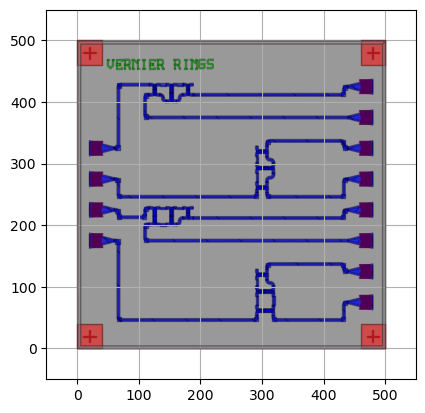

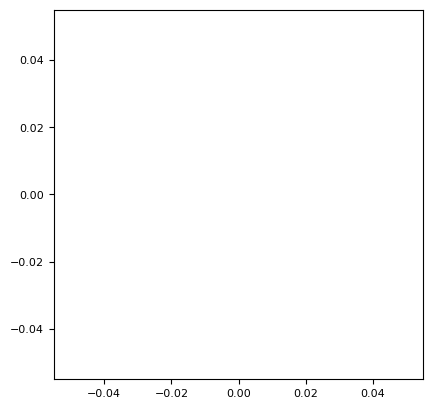

In [306]:
drc_layout = ak_chip.DrcLayout(drc_results=drc_results)
drc_layout.visualize()

# Save the Design

Save the DRC-clean layout to disk.

In [307]:
ak_chip_layout.write_gdsii('ak_chip.gds')

/svr/datavolume/users/spdc_21/notebooks/my_project_PRG/ak_chip.gds

# Submit your design

To facilitate the submission, use the following set of commands to submit the design. The design will be automatically uploaded to our submission server and versioned. You can submit designs all the way till the deadline.

In [264]:
from ccrate.client import CcrateClient
cc = CcrateClient(server_url='http://wsmaredsous.intec.ugent.be:1919/ccrate',
                  project="pic2025")  # make sure you submit to the right project
cc.ping() # Test connectivity to the server

Ping Successful


True

To submit your design all you have to do is to use the **submit_gds** function and pass the the gds file name:

In [265]:
# the line below is commented out. Uncomment it to submit the design

cc.submit_gds('ak_chip.gds', comment='chip_trial3')

'File successfully submitted'